# Clasificación de 3 escenas con CNN

Se entrenan dos variantes de red convolucional **secuencial** sobre el dataset
local de 3 escenas (`coast`, `forest`, `highway`; 958 imágenes: 360 de costa,
328 de bosque y 270 de autopista, es decir, un reparto aproximado de 38/34/28 %)
y cada una guarda sus resultados en una carpeta independiente:

| Variante | Carpeta | Descripción |
|---|---|---|
| CNN base | `resultados/cnn/base/` | Réplica del cuaderno del profesor: `Rescaling(1/255)` y tres bloques de 8 → 16 → 32 filtros, `Flatten` + `Dense(3, softmax)`. |
| CNN mejorada | `resultados/cnn/mejorada/` | Más filtros (32-64-128), `BatchNormalization`, `GlobalAveragePooling`, `Dropout`, augmentación y `class_weight` para el desbalance. |

Las imágenes se redimensionan a 128×128 y se cargan **sin normalizar**: la capa
`Rescaling(1/255)` vive dentro de los dos modelos, igual que en el cuaderno
base del profesor. El split es el común del reto: 75 % train, 15 % validación y
25 % test, estratificado con semilla 20 (`resultados/split.json`). El test
**no** se usa para early stopping.

Los modelos ya entrenados se cargan por defecto desde `resultados/`. Para volver
a entrenarlos, cambia `FORCE_RETRAIN = True` en la celda de configuración.

## Configuración

In [1]:
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from keras import layers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.layers import (
    Activation,
    BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    GlobalAveragePooling2D,
    Input,
    MaxPooling2D,
    Rescaling,
)
from keras.models import Sequential
from keras.optimizers import Adam

import common_3scenes as cs

FORCE_RETRAIN = False
sns.set_theme(style="whitegrid", context="notebook")
keras.utils.set_random_seed(cs.SEED)
np.random.seed(cs.SEED)

I0000 00:00:1794936506.183125  103762 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794936508.585117  103762 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Carga del dataset y split común

In [2]:
data = cs.load_split_data()
X_train = data["X_train"].astype("float32")
X_val = data["X_val"].astype("float32")
X_test = data["X_test"].astype("float32")
y_train_labels = data["y_train"]
y_val_labels = data["y_val"]
y_test_labels = data["y_test"]
test_paths = data["test_paths"]

y_train = cs.one_hot(y_train_labels)
y_val = cs.one_hot(y_val_labels)

# Class weights for the unbalanced training set (approx. 38/34/28 %).
class_counts = {name: int(np.sum(y_train_labels == name)) for name in cs.CLASSES}
total_train = sum(class_counts.values())
class_weight = {
    index: total_train / (len(cs.CLASSES) * class_counts[name])
    for index, name in enumerate(cs.CLASSES)
}

print("Train:", X_train.shape, "| Validación:", X_val.shape, "| Test:", X_test.shape)
print("Distribución de test:", {name: int(np.sum(y_test_labels == name)) for name in cs.CLASSES})
print("Distribución de train:", class_counts)
print(
    "class_weight:",
    {name: round(class_weight[index], 3) for index, name in enumerate(cs.CLASSES)},
)

Train: (610, 128, 128, 3) | Validación: (108, 128, 128, 3) | Test: (240, 128, 128, 3)
Distribución de test: {'coast': 90, 'forest': 82, 'highway': 68}
Distribución de train: {'coast': 229, 'forest': 209, 'highway': 172}
class_weight: {'coast': 0.888, 'forest': 0.973, 'highway': 1.182}


## Arquitecturas

La **CNN base** replica la arquitectura del cuaderno del profesor
(`3scenesCNN.ipynb`): entrada de 128×128×3, `Rescaling(1/255)` y tres bloques
`Conv2D(3×3, padding="same", activation="relu") + MaxPooling2D` con 8, 16 y 32
filtros, seguidos de `Flatten()` y `Dense(3, activation="softmax")`. Se entrena
15 épocas con `Adam(1e-3)`, `categorical_crossentropy` y batch de 32, sin
augmentación ni callbacks.

La **CNN mejorada** mantiene la estructura "bloques convolucionales → cabeza
densa" y añade lo que a la base le falta:

* Bloques `Conv2D(f, 3×3, padding="same", use_bias=False) → BatchNormalization → ReLU → MaxPooling2D` con `f` = 32, 64 y 128.
* Augmentación **solo durante el entrenamiento**: `RandomFlip("horizontal")`, `RandomRotation(0.08)`, `RandomZoom(0.1)` y `RandomContrast(0.1)`. Las capas viven **dentro del modelo** y Keras las desactiva automáticamente en inferencia.
* Cabeza ligera: `GlobalAveragePooling2D() → Dropout(0.4) → Dense(3, softmax)`.
* `class_weight` para compensar el desbalance del train.
* `EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True)` y `ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)` con un máximo de 40 épocas (la v2 cambia este régimen: ver más abajo).

### Nota sobre `Adam(learning_rate=1e-3, decay=1e-3/50)` y Keras 3

El cuaderno original del profesor compila el optimizador como
`Adam(learning_rate=1e-3, decay=1e-3/50)`. El argumento `decay` **fue eliminado
en Keras 3**: los schedules de learning rate ahora se pasan como objetos (por
ejemplo `keras.optimizers.schedules.ExponentialDecay`) o se gestionan con
callbacks como `ReduceLROnPlateau`.

Decisión: usar `Adam(learning_rate=1e-3)` sin decay en la CNN base, para
replicar la arquitectura y el flujo del cuaderno original con la API actual de
Keras (es una decisión defendible en la defensa oral). La CNN mejorada controla
el learning rate con `ReduceLROnPlateau`, que cumple el mismo papel de reducir
el paso de aprendizaje a medida que avanza el entrenamiento.

In [3]:
def build_base_cnn():
    model = Sequential(
        [
            Input(shape=(128, 128, 3)),
            Rescaling(1.0 / 255),
            Conv2D(8, (3, 3), padding="same", activation="relu"),
            MaxPooling2D((2, 2)),
            Conv2D(16, (3, 3), padding="same", activation="relu"),
            MaxPooling2D((2, 2)),
            Conv2D(32, (3, 3), padding="same", activation="relu"),
            MaxPooling2D((2, 2)),
            Flatten(),
            Dense(len(cs.CLASSES), activation="softmax"),
        ],
        name="cnn_base_3scenes",
    )
    model.compile(
        loss="categorical_crossentropy",
        optimizer=Adam(learning_rate=1e-3),
        metrics=["accuracy"],
    )
    return model


def conv_block(x, filters):
    x = Conv2D(filters, (3, 3), padding="same", use_bias=False)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(filters, (3, 3), padding="same", use_bias=False)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    return MaxPooling2D((2, 2))(x)


def build_improved_cnn():
    inputs = Input(shape=(128, 128, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.10)(x)
    x = layers.RandomTranslation(0.08, 0.08)(x)
    x = Rescaling(1.0 / 255)(x)
    x = conv_block(x, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation="relu")(x)
    x = Dropout(0.4)(x)
    outputs = Dense(len(cs.CLASSES), activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="cnn_improved_3scenes")
    model.compile(
        loss="categorical_crossentropy",
        optimizer=Adam(learning_rate=1e-3),
        metrics=["accuracy"],
    )
    return model

## Entrenamiento o carga desde caché

In [4]:
def fit_base(model):
    history, seconds = cs.train_keras_model(
        model, X_train, y_train, X_val, y_val, epochs=15, batch_size=32
    )
    return model, history, seconds


def evaluate_base(model, history, training_seconds):
    predicted_idx, probabilities, inference_ms = cs.predict_keras(model, X_test)
    predicted = np.array(cs.CLASSES)[predicted_idx]
    metrics = cs.compute_metrics(
        name="CNN base",
        family="CNN",
        y_true=y_test_labels,
        y_pred=predicted,
        y_prob=probabilities,
        params=model.count_params(),
        trainable_params=sum(np.prod(weight.shape) for weight in model.trainable_weights),
        training_seconds=training_seconds,
        inference_ms=inference_ms,
        epochs=len(history.history["loss"]),
        hyperparameters={
            "filters": [8, 16, 32],
            "optimizer": "Adam",
            "lr": 1e-3,
            "batch_size": 32,
            "epochs": 15,
            "augmentation": False,
        },
        notes="Sequential replica of the professor's base notebook (Adam decay removed in Keras 3).",
    )
    cs.save_results(
        "cnn/base",
        metrics,
        y_test_labels,
        predicted,
        probabilities,
        test_paths=test_paths,
        history=history,
        model=model,
    )
    return metrics


def fit_improved(model):
    callbacks = [
        EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5, verbose=1),
    ]
    history, seconds = cs.train_keras_model(
        model,
        X_train,
        y_train,
        X_val,
        y_val,
        epochs=40,
        batch_size=32,
        callbacks=callbacks,
        class_weight=class_weight,
    )
    return model, history, seconds


def evaluate_improved(model, history, training_seconds):
    predicted_idx, probabilities, inference_ms = cs.predict_keras(model, X_test)
    predicted = np.array(cs.CLASSES)[predicted_idx]
    metrics = cs.compute_metrics(
        name="CNN mejorada",
        family="CNN",
        y_true=y_test_labels,
        y_pred=predicted,
        y_prob=probabilities,
        params=model.count_params(),
        trainable_params=sum(np.prod(weight.shape) for weight in model.trainable_weights),
        training_seconds=training_seconds,
        inference_ms=inference_ms,
        epochs=len(history.history["loss"]),
        hyperparameters={
            "filters": [32, 64, 128],
            "optimizer": "Adam",
            "lr": 1e-3,
            "batch_size": 32,
            "epochs_max": 40,
            "augmentation": True,
            "dropout": 0.4,
            "dense_units": 128,
            "early_stopping": 8,
            "class_weight": True,
        },
        notes="CNN with two convolutions per block, BatchNorm, GAP, Dense(128), Dropout, augmentation and class weights (same recipe as reto 2).",
    )
    cs.save_results(
        "cnn/mejorada",
        metrics,
        y_test_labels,
        predicted,
        probabilities,
        test_paths=test_paths,
        history=history,
        model=model,
    )
    return metrics

In [5]:
model_base, history_base, metrics_base, retrained_base = cs.load_or_train(
    "cnn/base",
    build_model=build_base_cnn,
    fit_model=fit_base,
    evaluate_model=evaluate_base,
    force=FORCE_RETRAIN,
)
print("Accuracy en test:", round(metrics_base["accuracy"], 4))

[cache] Using trained model from /home/chewi/Documentos/uni/vision-por-computador/guia-4/reto-1/resultados/cnn/base
Accuracy en test: 0.9042


E0000 00:00:1794936512.108382  103762 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [6]:
model_improved, history_improved, metrics_improved, retrained_improved = cs.load_or_train(
    "cnn/mejorada",
    build_model=build_improved_cnn,
    fit_model=fit_improved,
    evaluate_model=evaluate_improved,
    force=FORCE_RETRAIN,
)
print("Accuracy en test:", round(metrics_improved["accuracy"], 4))

[cache] Using trained model from /home/chewi/Documentos/uni/vision-por-computador/guia-4/reto-1/resultados/cnn/mejorada
Accuracy en test: 0.8708


In [7]:
model_base.summary()
print(f"\nParámetros de la CNN base: {model_base.count_params():,}")

model_improved.summary()
print(f"\nParámetros de la CNN mejorada: {model_improved.count_params():,}")

Model: "cnn_base_3scenes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 8)    │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │        24,579 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,835 (358.73 KB)

 Trainable params: 30,611 (119.57 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 61,224 (239.16 KB)

... (4 outputs left out)

 Trainable params: 304,355 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 608,712 (2.32 MB)


Parámetros de la CNN mejorada: 305,251


## Comparación de las dos variantes

In [8]:
comparison = pd.DataFrame(
    [
        {
            "model": metrics_base["name"],
            "accuracy": metrics_base["accuracy"],
            "f1_macro": metrics_base["f1_macro"],
            "parameters": metrics_base["parameters"],
            "training_seconds": metrics_base["training_seconds"],
        },
        {
            "model": metrics_improved["name"],
            "accuracy": metrics_improved["accuracy"],
            "f1_macro": metrics_improved["f1_macro"],
            "parameters": metrics_improved["parameters"],
            "training_seconds": metrics_improved["training_seconds"],
        },
    ]
)
display = comparison.rename(
    columns={
        "model": "Modelo",
        "accuracy": "Accuracy",
        "f1_macro": "F1 macro",
        "parameters": "Parámetros",
        "training_seconds": "Entrenamiento (s)",
    }
)
display.round(4)

,Modelo,Accuracy,F1 macro,Parámetros,Entrenamiento (s)
0,CNN base,0.9042,0.9012,30611,6.51
1,CNN mejorada,0.8708,0.8608,305251,482.45


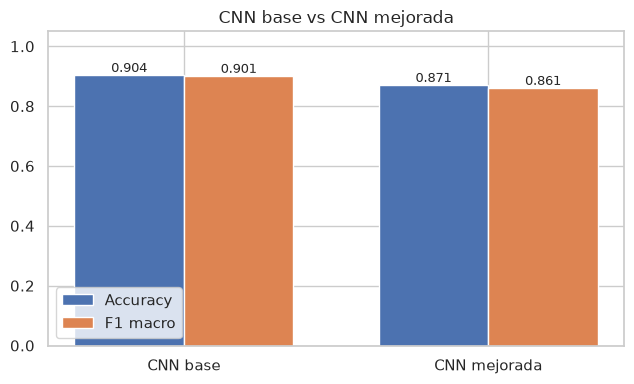

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4))
positions = np.arange(len(comparison))
width = 0.36
ax.bar(positions - width / 2, comparison["accuracy"], width, label="Accuracy")
ax.bar(positions + width / 2, comparison["f1_macro"], width, label="F1 macro")
ax.set_xticks(positions, comparison["model"])
ax.set_ylim(0, 1.05)
ax.set_title("CNN base vs CNN mejorada")
ax.legend()
for index, (accuracy, f1_value) in enumerate(
    zip(comparison["accuracy"], comparison["f1_macro"])
):
    ax.text(index - width / 2, accuracy + 0.01, f"{accuracy:.3f}", ha="center", fontsize=9)
    ax.text(index + width / 2, f1_value + 0.01, f"{f1_value:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## Observaciones

* La CNN base es deliberadamente simple y sin regularización, como en el
  cuaderno del profesor, por lo que se espera que sobreajuste (la accuracy de
  entrenamiento sube por encima de la de validación). Los números exactos
  quedan en la tabla de la sección anterior y en
  `resultados/cnn/base/metrics.json`.
* La CNN mejorada ataca ese sobreajuste con más filtros por bloque,
  `BatchNormalization`, `Dropout`, `GlobalAveragePooling`, augmentación y
  `class_weight`, y añade callbacks para parar a tiempo y reducir el learning
  rate. El coste es un modelo con más parámetros y un entrenamiento más largo
  en CPU.
* El flag `FORCE_RETRAIN = False` permite reutilizar los modelos ya guardados
  y evitar ese coste al revisar el cuaderno.
* La comparación completa con DenseNet121 y con los modelos de machine
  learning (IC 95 % por bootstrap, McNemar, matrices de confusión, curvas)
  está en `reto-1.ipynb` y en `resultados/comparacion/`.

## Versión 2 de la CNN mejorada: ajuste de hiperparámetros

La primera versión (`resultados/cnn/mejorada/`) quedó **3.3 puntos por debajo**
de la CNN base, y el `history.csv` dice por qué: durante las primeras 13 épocas
el `val_accuracy` se quedó clavado en 0.3796 (el modelo predijo prácticamente
una sola clase) mientras el `val_loss` subía hasta 2.8, y el entrenamiento se
cortó en la época 40 cuando la validación todavía venía mejorando (0.926 en las
épocas 34, 37, 39 y 40). Es el patrón de augmentación demasiado agresiva para
610 imágenes de entrenamiento, learning rate inicial alto para una red con
`BatchNormalization`, y `EarlyStopping` mirando una `val_accuracy` ruidosa
(108 imágenes) en vez de `val_loss`.

Esta segunda iteración cambia cuatro cosas, cada una atada a lo que el
enunciado permite tocar:

| Cambio | Antes (v1) | Ahora (v2) | Por qué |
|---|---|---|---|
| Augmentación | flip + rotación 0.08 + zoom 0.10 + traslación 0.08 | flip + rotación 0.05 | Con 610 imágenes, cuatro transformaciones fuertes destruyen la señal de color que separa costa de autopista |
| Learning rate | 1e-3 | 3e-4 | Con `BatchNormalization` el 1e-3 desestabiliza las estadísticas por lote |
| Función de costo | crossentropy pura | crossentropy con `label_smoothing=0.05` | Evita que el modelo se vuelva sobreconfiado con etiquetas ruidosas y mejora la calibración |
| Callbacks | `EarlyStopping(val_accuracy, paciencia 8)`, 40 épocas | `EarlyStopping(val_loss, paciencia 20)`, hasta 100 épocas | La validación es pequeña y ruidosa: `val_loss` es más estable y no corta una curva que aún baja |

La estructura se mantiene (32-64-128, dos convoluciones por bloque,
`BatchNormalization`, `GlobalAveragePooling`, `Dense(128)`, `Dropout(0.4)` y
`class_weight`), porque el problema no era la capacidad del modelo sino el
régimen de entrenamiento. Los resultados van a `resultados/cnn/mejorada_v2/`,
así que la v1 se conserva como evidencia de la iteración.


In [10]:
def build_improved_cnn_v2():
    inputs = Input(shape=(128, 128, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.05)(x)
    x = Rescaling(1.0 / 255)(x)
    x = conv_block(x, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation="relu")(x)
    x = Dropout(0.4)(x)
    outputs = Dense(len(cs.CLASSES), activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="cnn_improved_v2_3scenes")
    model.compile(
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
        optimizer=Adam(learning_rate=3e-4),
        metrics=["accuracy"],
    )
    return model


def fit_improved_v2(model):
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-6, verbose=1),
    ]
    history, seconds = cs.train_keras_model(
        model,
        X_train,
        y_train,
        X_val,
        y_val,
        epochs=100,
        batch_size=32,
        callbacks=callbacks,
        class_weight=class_weight,
    )
    return model, history, seconds


def evaluate_improved_v2(model, history, training_seconds):
    predicted_idx, probabilities, inference_ms = cs.predict_keras(model, X_test)
    predicted = np.array(cs.CLASSES)[predicted_idx]
    metrics = cs.compute_metrics(
        name="CNN mejorada v2",
        family="CNN",
        y_true=y_test_labels,
        y_pred=predicted,
        y_prob=probabilities,
        params=model.count_params(),
        trainable_params=sum(np.prod(weight.shape) for weight in model.trainable_weights),
        training_seconds=training_seconds,
        inference_ms=inference_ms,
        epochs=len(history.history["loss"]),
        hyperparameters={
            "filters": [32, 64, 128],
            "convs_per_block": 2,
            "optimizer": "Adam",
            "lr": 3e-4,
            "loss": "categorical_crossentropy",
            "label_smoothing": 0.05,
            "batch_size": 32,
            "epochs_max": 100,
            "early_stopping": "val_loss, patience=20",
            "augmentation": "flip + rotation 0.05",
            "class_weight": True,
            "iteration": 2,
        },
        notes=(
            "Second iteration of the improved CNN: weaker augmentation, learning rate 3e-4, "
            "label smoothing and early stopping on val_loss after v1 collapsed on validation."
        ),
    )
    cs.save_results(
        "cnn/mejorada_v2",
        metrics,
        y_test_labels,
        predicted,
        probabilities,
        test_paths=test_paths,
        history=history,
        model=model,
    )
    return metrics


In [11]:
model_v2, history_v2, metrics_v2, retrained_v2 = cs.load_or_train(
    "cnn/mejorada_v2",
    build_model=build_improved_cnn_v2,
    fit_model=fit_improved_v2,
    evaluate_model=evaluate_improved_v2,
    force=FORCE_RETRAIN,
)
print("Accuracy en test:", round(metrics_v2["accuracy"], 4))
epochs_v2 = len(history_v2.history["loss"]) if hasattr(history_v2, "history") else len(history_v2)
print(f"Parámetros: {model_v2.count_params():,} | Épocas entrenadas: {epochs_v2}")


[cache] Using trained model from /home/chewi/Documentos/uni/vision-por-computador/guia-4/reto-1/resultados/cnn/mejorada_v2
Accuracy en test: 0.8917
Parámetros: 305,251 | Épocas entrenadas: 51


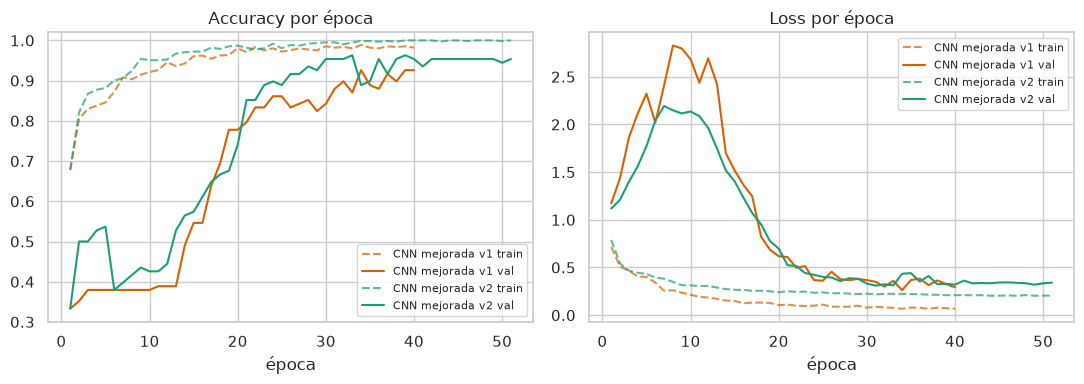

In [12]:
if history_v2 is None:
    print("[aviso] Sin history de la v2 todavia: entrena el modelo para ver las curvas.")
else:
    def series(history, key):
        return history.history[key] if hasattr(history, "history") else history[key]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for history, label, colour in (
        (history_improved, "CNN mejorada v1", "#d95f02"),
        (history_v2, "CNN mejorada v2", "#1b9e77"),
    ):
        axes[0].plot(series(history, "accuracy"), "--", color=colour, alpha=0.7, label=f"{label} train")
        axes[0].plot(series(history, "val_accuracy"), "-", color=colour, label=f"{label} val")
        axes[1].plot(series(history, "loss"), "--", color=colour, alpha=0.7, label=f"{label} train")
        axes[1].plot(series(history, "val_loss"), "-", color=colour, label=f"{label} val")
    axes[0].set_title("Accuracy por época")
    axes[0].set_xlabel("época")
    axes[0].set_ylim(0.3, 1.02)
    axes[1].set_title("Loss por época")
    axes[1].set_xlabel("época")
    for ax in axes:
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


## Qué muestra la iteración

* Si la v2 supera a la v1 y a la CNN base, el mensaje del informe es que la
  arquitectura por sí sola no bastaba: el régimen de entrenamiento
  (augmentación, learning rate, función de costo y paciencia del early
  stopping) era la mitad del problema.
* Si la v2 no supera a la base, la conclusión honesta es que con 610 imágenes
  de entrenamiento una CNN desde cero no le gana a los descriptores clásicos y
  que el salto real de este dataset está en el preentrenamiento (DenseNet121).
  En ese caso hay que decirlo así en `reto-1.ipynb`, no maquillar la tabla.
* Las dos versiones quedan guardadas (`cnn/mejorada/` y `cnn/mejorada_v2/`), de
  modo que la comparación de `reto-1.ipynb` incluye las dos y el lector ve el
  efecto del ajuste.
